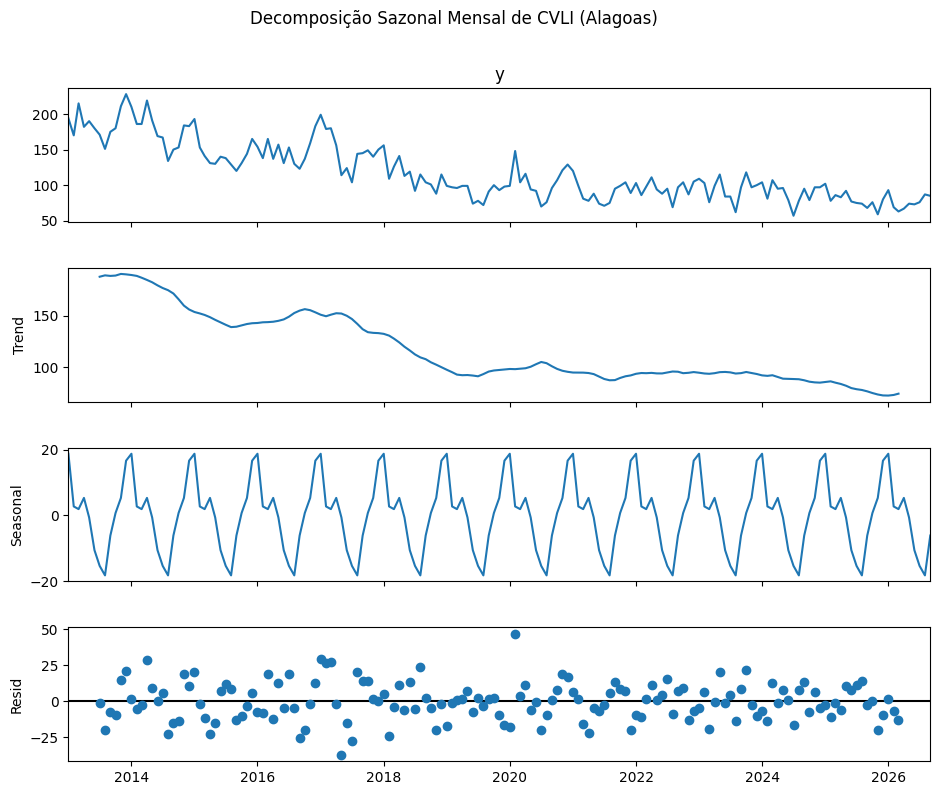

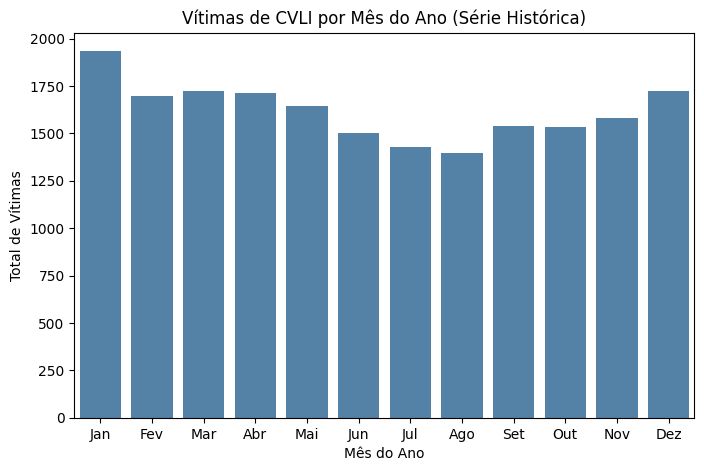

--- RESULTADOS DA CORRELAÇÃO DE SPEARMAN (2022) ---
População x Contagem de Vítimas: Coeficiente = 0.728 | p-valor = 0.00000
População x Taxa por 100k hab.:  Coeficiente = 0.127 | p-valor = 0.205


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import spearmanr

df = pd.read_csv('painel.csv', parse_dates=['mes'])

df_estado = df.groupby('mes')['y'].sum().reset_index()
df_estado = df_estado.set_index('mes')
df_estado = df_estado.sort_index()

decomposicao = seasonal_decompose(df_estado['y'], model='additive', period=12)

fig_decomp = decomposicao.plot()
fig_decomp.set_size_inches(10, 8)
plt.suptitle('Decomposição Sazonal Mensal de CVLI (Alagoas)', y=1.02)
plt.savefig('fig_rq1_decomposicao.png', bbox_inches='tight', dpi=300)
plt.show()

vitimas_por_mes_ano = df.groupby('m')['y'].sum()

plt.figure(figsize=(8, 5))
sns.barplot(x=vitimas_por_mes_ano.index, y=vitimas_por_mes_ano.values, color='steelblue')
plt.title('Vítimas de CVLI por Mês do Ano (Série Histórica)')
plt.xlabel('Mês do Ano')
plt.ylabel('Total de Vítimas')
plt.xticks(range(0, 12), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
plt.savefig('fig_rq1_mes.png', bbox_inches='tight', dpi=300)
plt.show()

df_2022 = df[df['ano'] == 2022]

df_mun_2022 = df_2022.groupby('cidade').agg(
    vitimas_2022=('y', 'sum'),
    populacao=('pop', 'first')
).reset_index()

df_mun_2022['taxa_100k'] = (df_mun_2022['vitimas_2022'] / df_mun_2022['populacao']) * 100000

coef_contagem, pval_contagem = spearmanr(df_mun_2022['populacao'], df_mun_2022['vitimas_2022'])
coef_taxa, pval_taxa = spearmanr(df_mun_2022['populacao'], df_mun_2022['taxa_100k'])

print("--- RESULTADOS DA CORRELAÇÃO DE SPEARMAN (2022) ---")
print(f"População x Contagem de Vítimas: Coeficiente = {coef_contagem:.3f} | p-valor = {pval_contagem:.5f}")
print(f"População x Taxa por 100k hab.:  Coeficiente = {coef_taxa:.3f} | p-valor = {pval_taxa:.3f}")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')